In [2]:
# === Imports ===
import numpy as np  # Array operations
import matplotlib.pyplot as plt  # Plotting
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap, to_rgba_array # For the color scheme
import pandas as pd  # Data handling
import pyp2options  # Custom library --> Calibrations
from astropy.coordinates import SkyCoord  # Astronomical coordinate handling
import astropy.units as u  # Physical units
import scipy.optimize as spopt  # Optimization algorithms
import scipy.stats as st
from scipy.stats import gaussian_kde
import sys
#from matplotlib.backends.backend_pdf import PdfPages  # Save multiple figures into a PDF

In [3]:
# === Color Scheme ===
def discretemap(colormap, hexclrs):
    """
    Produce a colormap from a list of discrete colors without interpolation.
    """
    clrs = to_rgba_array(hexclrs)
    clrs = np.vstack([clrs[0], clrs, clrs[-1]])
    cdict = {}
    for ki, key in enumerate(('red','green','blue')):
        cdict[key] = [ (i/(len(clrs)-2.), clrs[i, ki], clrs[i+1, ki]) for i in range(len(clrs)-1) ]
    return LinearSegmentedColormap(colormap, cdict)

class TOLcmaps:
    """
    Simplified TOLcmaps with only 'nightfall_discrete' and 'YlOrBr_discrete'.
    """
    def __init__(self):
        self.cmap = None
        self.cname = None
        self.namelist = ('nightfall_discrete', 'YlOrBr_discrete')
        self.funcdict = {
            'nightfall_discrete': self.__nightfall_discrete,
            'YlOrBr_discrete': self.__YlOrBr_discrete,
        }

    def __nightfall_discrete(self):
        clrs = ['#125A56', '#238F9D', '#60BCE9', '#C6DBED', '#ECEADA',
                '#F9D576', '#FD9A44', '#E94C1F', '#A01813']
        self.cmap = discretemap(self.cname, clrs)
        self.cmap.set_bad('#FFFFFF')

    def __YlOrBr_discrete(self):
        clrs = ['#FFFFE5', '#FFF7BC', '#FEE391', '#FEC44F', '#FB9A29',
                '#EC7014', '#CC4C02', '#993404', '#662506']
        self.cmap = discretemap(self.cname, clrs)
        self.cmap.set_bad('#888888')

    def show(self):
        print(' '.join(self.namelist))

    def get(self, cname='nightfall_discrete'):
        self.cname = cname
        if cname in self.funcdict:
            self.funcdict[cname]()
            return self.cmap
        else:
            raise ValueError(f"Colormap {cname} is not available. Choose from {self.namelist}.")

def tol_cmap(colormap=None):
    """
    Return matplotlib colormap. Only 'nightfall_discrete' and 'YlOrBr_discrete' supported.
    """
    obj = TOLcmaps()
    if colormap is None:
        return obj.namelist
    return obj.get(colormap)

In [4]:
# === Defined Parameters ===
field_name = 'MISHAPS_F1_DITH0'  # Field identifier
chip_id = 'N10'  # Chip identifier
magnitude_band_1 = 'r'  # Band used for magnitude measurement
magnitude_band_2 = 'g'
color_band_1 = 'r'  # First band for color (e.g. r-z)
color_band_2 = 'z'  # Second band for color
color_band_3 = 'g'
color_band_4 = 'i'
field_chip_label = f"{field_name}_{chip_id}"  # Combined label for file references

# CMD (Color-Magnitude Diagram) Parameters
default_color_cut_rz = 1.06
default_color_cut_gi = 1.06
# magnitude_cut = 17.3
magnitude_cut_rz = 17.3
magnitude_cut_g = 19
magnitude_cut_i = 17.5
color_range_min = 0.0
color_range_max = 2.0
msto_shift_value = 3.5  # Main Sequence Turn-Off shift

# Adjust defaults for specific color combinations
if color_band_2 == "i" and color_band_1 == "g":
    # default_color_cut = 0.46
    default_color_cut_rz = 0.6
    default_color_cut_gi = 1.2
    color_range_max = 1.0
    msto_shift_value = 3.0

In [5]:
# Enable interactive plots if enough command-line arguments are provided
interactive_mode = False
if len(sys.argv) >= 6:
    interactive_mode = True

# Optionally override color and magnitude cuts
if len(sys.argv) >= 7:
    default_color_cut = float(sys.argv[6])
    print("Color cut set to:", default_color_cut)

if len(sys.argv) >= 8:
    magnitude_cut = float(sys.argv[7])
    print("Magnitude cut set to:", magnitude_cut)

print("Using magnitude and color bands:", magnitude_band_1, magnitude_band_2, color_band_1, color_band_2, 
      color_band_3, color_band_4)

Using magnitude and color bands: r g r z g i


In [6]:
# Optional positional filtering via RA/Dec limits
ra_min, ra_max = -1, -1
dec_min, dec_max = -1, -1
apply_position_cut = False

if len(sys.argv) >= 9:
    ra_min = float(sys.argv[8])
    ra_max = float(sys.argv[9])
    dec_min = float(sys.argv[10])
    dec_max = float(sys.argv[11])
    apply_position_cut = True

In [7]:
# === Load in MISHAPS File ===
catalog_path = "/home/bernthold.17/SURP2025/Data_Files/" + field_chip_label + ".cmd.calibrate_ps"
contents = pd.read_csv(catalog_path, header = None, sep = '\\s+')

In [8]:
# === Apply Column Headers ===
column_labels = ['ID', 'RA_z', 'Dec_z', 'ID_z', 'X_z', 'Y_z', 'mis_z', 'mis_z_err', 'Sky_z', 'qflag_z', '?1z', '?2z',
       'RA_r', 'Dec_r', 'ID_r', 'X_r', 'Y_r', 'mis_r', 'mis_r_err', 'Sky_r', 'qflag_r', '?1r', '?2r',
       'RA_u', 'Dec_u', 'ID_u', 'X_u', 'Y_u', 'mis_u', 'mis_u_err', 'Sky_u', 'qflag_u', '?1u', '?2u',
       'RA_g', 'Dec_g', 'ID_g', 'X_g', 'Y_g', 'mis_g', 'mis_g_err', 'Sky_g', 'qflag_g', '?1g', '?2g',
       'RA_i', 'Dec_i', 'ID_i', 'X_i', 'Y_i', 'mis_i', 'mis_i_err', 'Sky_i', 'qflag_i', '?1i', '?2i',
       'RA_Y', 'Dec_Y', 'ID_Y', 'X_Y', 'Y_Y', 'mis_Y', 'mis_Y_err', 'Sky_Y', 'qflag_Y', '?1Y', '?2Y']
              
contents.columns = column_labels
#print(contents)

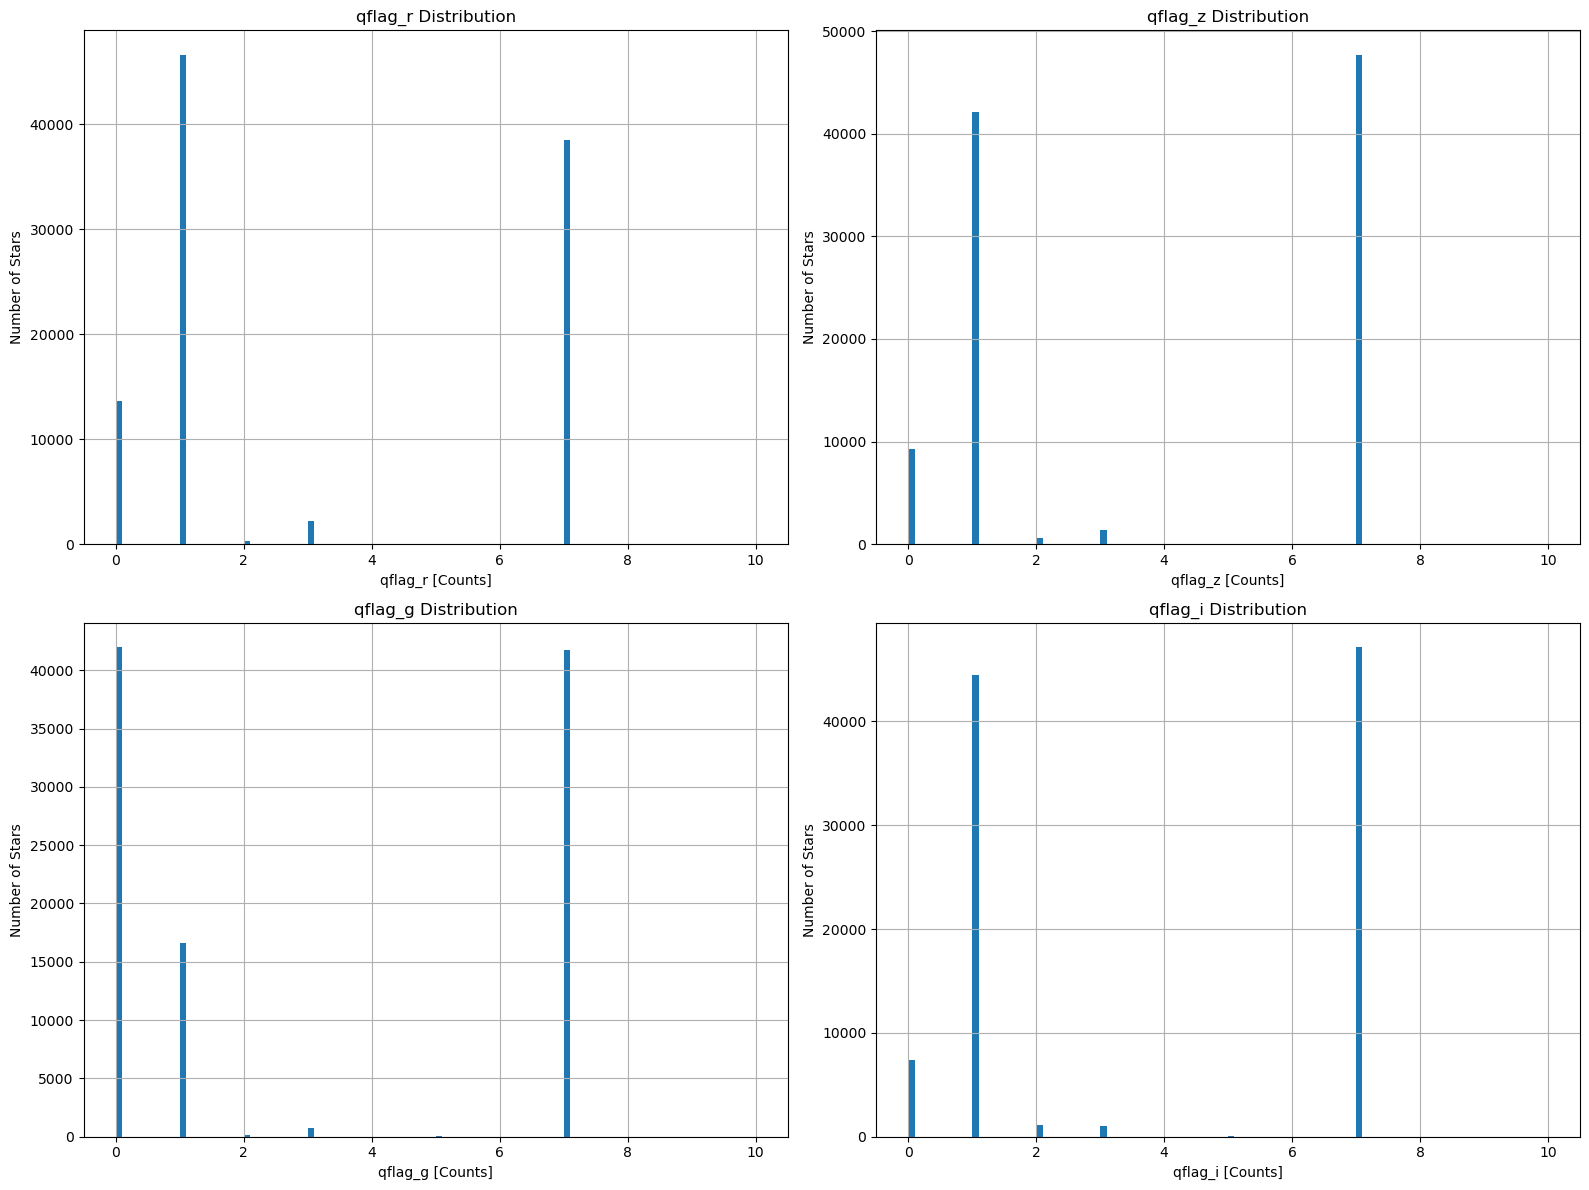

qflag_r: 0.90    7.0
0.95    7.0
0.98    7.0
0.99    7.0
Name: qflag_r, dtype: float64
qflag_z: 0.90    7.0
0.95    7.0
0.98    7.0
0.99    7.0
Name: qflag_z, dtype: float64
qflag_g: 0.90    7.0
0.95    7.0
0.98    7.0
0.99    7.0
Name: qflag_g, dtype: float64
qflag_i: 0.90    7.0
0.95    7.0
0.98    7.0
0.99    7.0
Name: qflag_i, dtype: float64


In [15]:
# === Determine Filter Values ===
# Quality flags --> qflag_mag

# Create one figure with 2 rows × 2 columns, each row height = 6
fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(2, 2, height_ratios=[6, 6])

# === Top-left: Quality Flag Distribution (r-band) ===
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(contents['qflag_r'], bins=100, range=(0, 10))
ax1.set_xlabel(f"qflag_{magnitude_band_1} [Counts]")
ax1.set_ylabel(f"Number of Stars")
ax1.set_title(f"qflag_{magnitude_band_1} Distribution")
ax1.grid(True)

# === Top-right: Quality Flag Distribution (z-band) ===
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(contents['qflag_z'], bins=100, range=(0, 10))
ax2.set_xlabel(f"qflag_{color_band_2} [Counts]")
ax2.set_ylabel(f"Number of Stars")
ax2.set_title(f"qflag_{color_band_2} Distribution")
ax2.grid(True)
             
# === Bottom-left: Quality Flag Distribution (g-band) ===
ax3 = fig.add_subplot(gs[1, 0])
ax3.hist(contents['qflag_g'], bins=100, range=(0, 10))
ax3.set_xlabel(f"qflag_{magnitude_band_2} [Counts]")
ax3.set_ylabel(f"Number of Stars")
ax3.set_title(f"qflag_{magnitude_band_2} Distribution")
ax3.grid(True)

# === Bottom-right: Quality Flag Distribution (i-band) ===
ax4 = fig.add_subplot(gs[1, 1])
ax4.hist(contents['qflag_i'], bins=100, range=(0, 10))
ax4.set_xlabel(f"qflag_{color_band_4} [Counts]")
ax4.set_ylabel(f"Number of Stars")
ax4.set_title(f"qflag_{color_band_4} Distribution")
ax4.grid(True)

plt.tight_layout()
plt.show()

# Quantiles
print("qflag_r:", contents['qflag_r'].quantile([0.90, 0.95, 0.98, 0.99]))
print("qflag_z:", contents['qflag_z'].quantile([0.90, 0.95, 0.98, 0.99]))
print("qflag_g:", contents['qflag_g'].quantile([0.90, 0.95, 0.98, 0.99]))
print("qflag_i:", contents['qflag_i'].quantile([0.90, 0.95, 0.98, 0.99]))

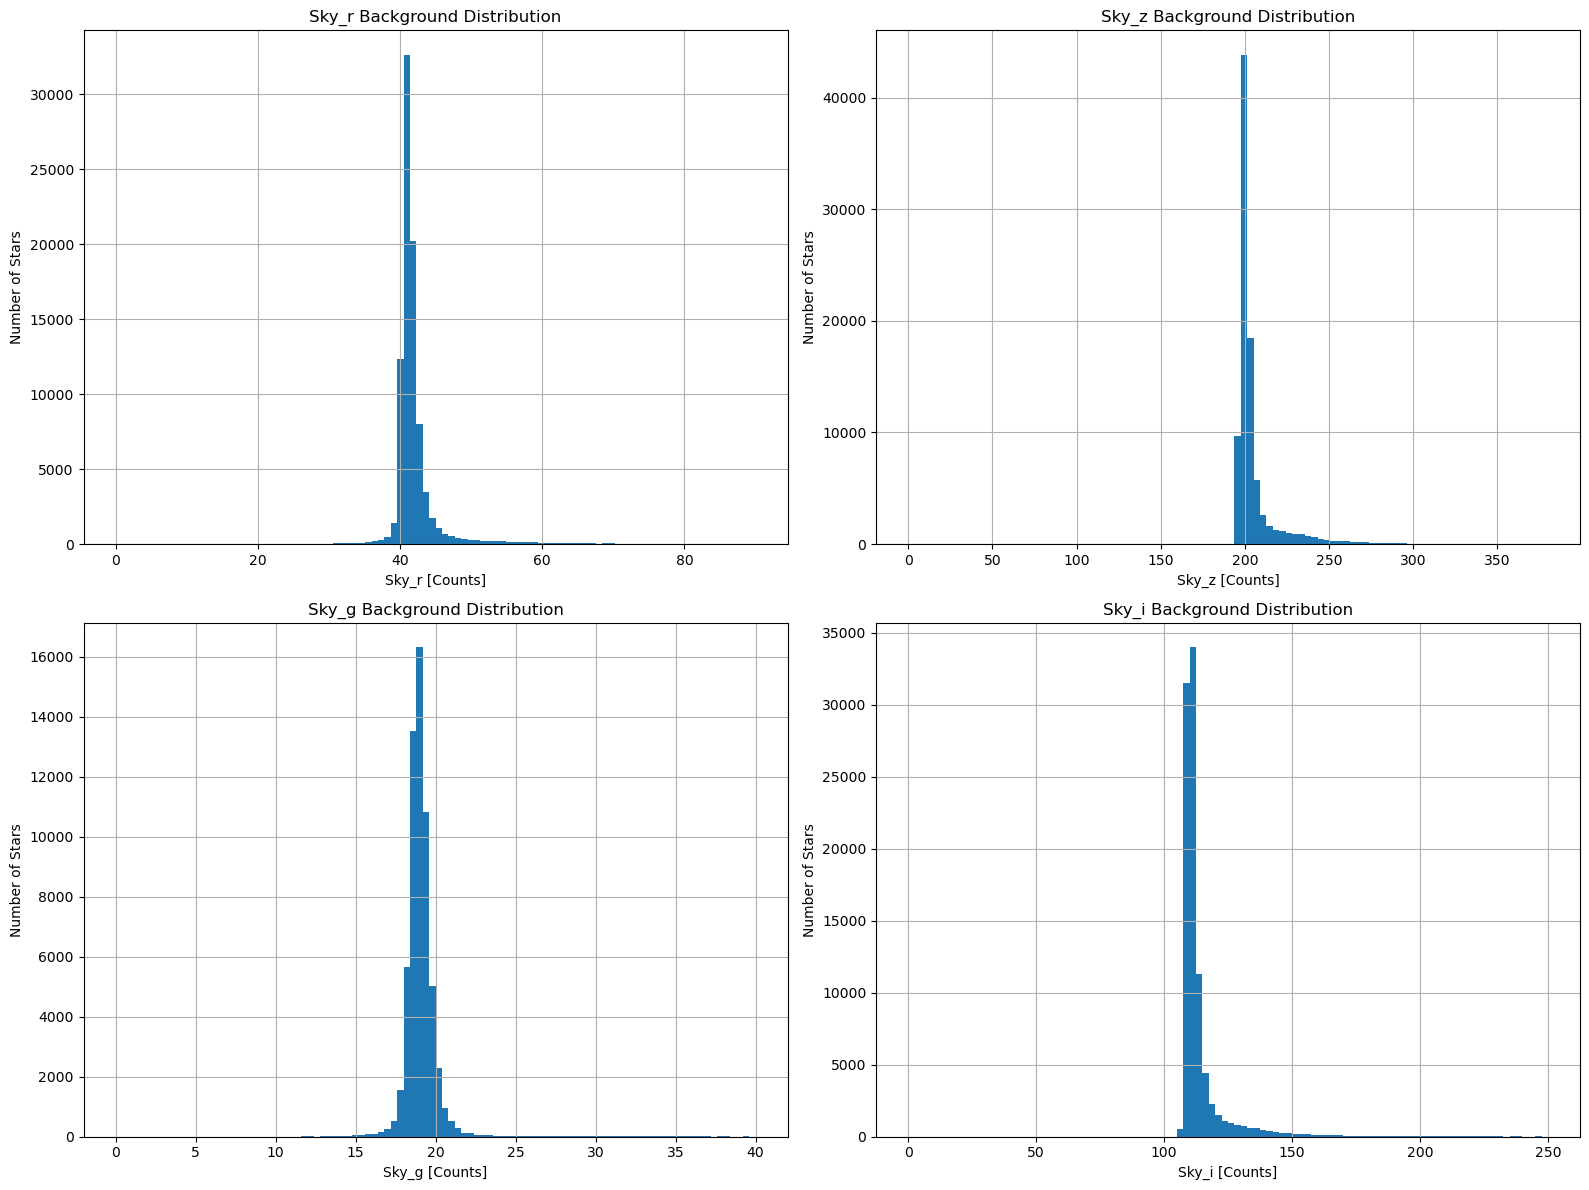

Sky_r: 0.90    43.86310
0.95    47.07310
0.98    56.27800
0.99    63.26147
Name: Sky_r, dtype: float64
Sky_z: 0.90    218.426080
0.95    235.777100
0.98    257.661588
0.99    275.605244
Name: Sky_z, dtype: float64
Sky_g: 0.90    19.887630
0.95    20.326565
0.98    21.202688
0.99    22.684416
Name: Sky_g, dtype: float64
Sky_i: 0.90    120.515360
0.95    132.492830
0.98    148.535512
0.99    162.826318
Name: Sky_i, dtype: float64


In [9]:
# Sky_mag background distribution

# Create one figure with 2 rows × 2 columns, each row height = 6
fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(2, 2, height_ratios=[6, 6])

# === Top-left: Sky_r Background Distribution (r-band) ===
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(contents['Sky_r'], bins=100, range=(0, 90))
ax1.set_xlabel(f"Sky_{magnitude_band_1} [Counts]")
ax1.set_ylabel(f"Number of Stars")
ax1.set_title(f"Sky_{magnitude_band_1} Background Distribution")
ax1.grid(True)

# === Top-right: Sky_z Background Distribution (z-band) ===
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(contents['Sky_z'], bins=100, range=(0, 380))
ax2.set_xlabel(f"Sky_{color_band_2} [Counts]")
ax2.set_ylabel(f"Number of Stars")
ax2.set_title(f"Sky_{color_band_2} Background Distribution")
ax2.grid(True)
             
# === Bottom-left: Sky_g Background Distribution (g-band) ===
ax3 = fig.add_subplot(gs[1, 0])
ax3.hist(contents['Sky_g'], bins=100, range=(0, 40))
ax3.set_xlabel(f"Sky_{magnitude_band_2} [Counts]")
ax3.set_ylabel(f"Number of Stars")
ax3.set_title(f"Sky_{magnitude_band_2} Background Distribution")
ax3.grid(True)

# === Bottom-right: Sky_i Background Distribution (i-band) ===
ax4 = fig.add_subplot(gs[1, 1])
ax4.hist(contents['Sky_i'], bins=100, range=(0, 250))
ax4.set_xlabel(f"Sky_{color_band_4} [Counts]")
ax4.set_ylabel(f"Number of Stars")
ax4.set_title(f"Sky_{color_band_4} Background Distribution")
ax4.grid(True)

plt.tight_layout()
plt.show()

# Quantiles
print("Sky_r:", contents['Sky_r'].quantile([0.90, 0.95, 0.98, 0.99]))
print("Sky_z:", contents['Sky_z'].quantile([0.90, 0.95, 0.98, 0.99]))
print("Sky_g:", contents['Sky_g'].quantile([0.90, 0.95, 0.98, 0.99]))
print("Sky_i:", contents['Sky_i'].quantile([0.90, 0.95, 0.98, 0.99]))

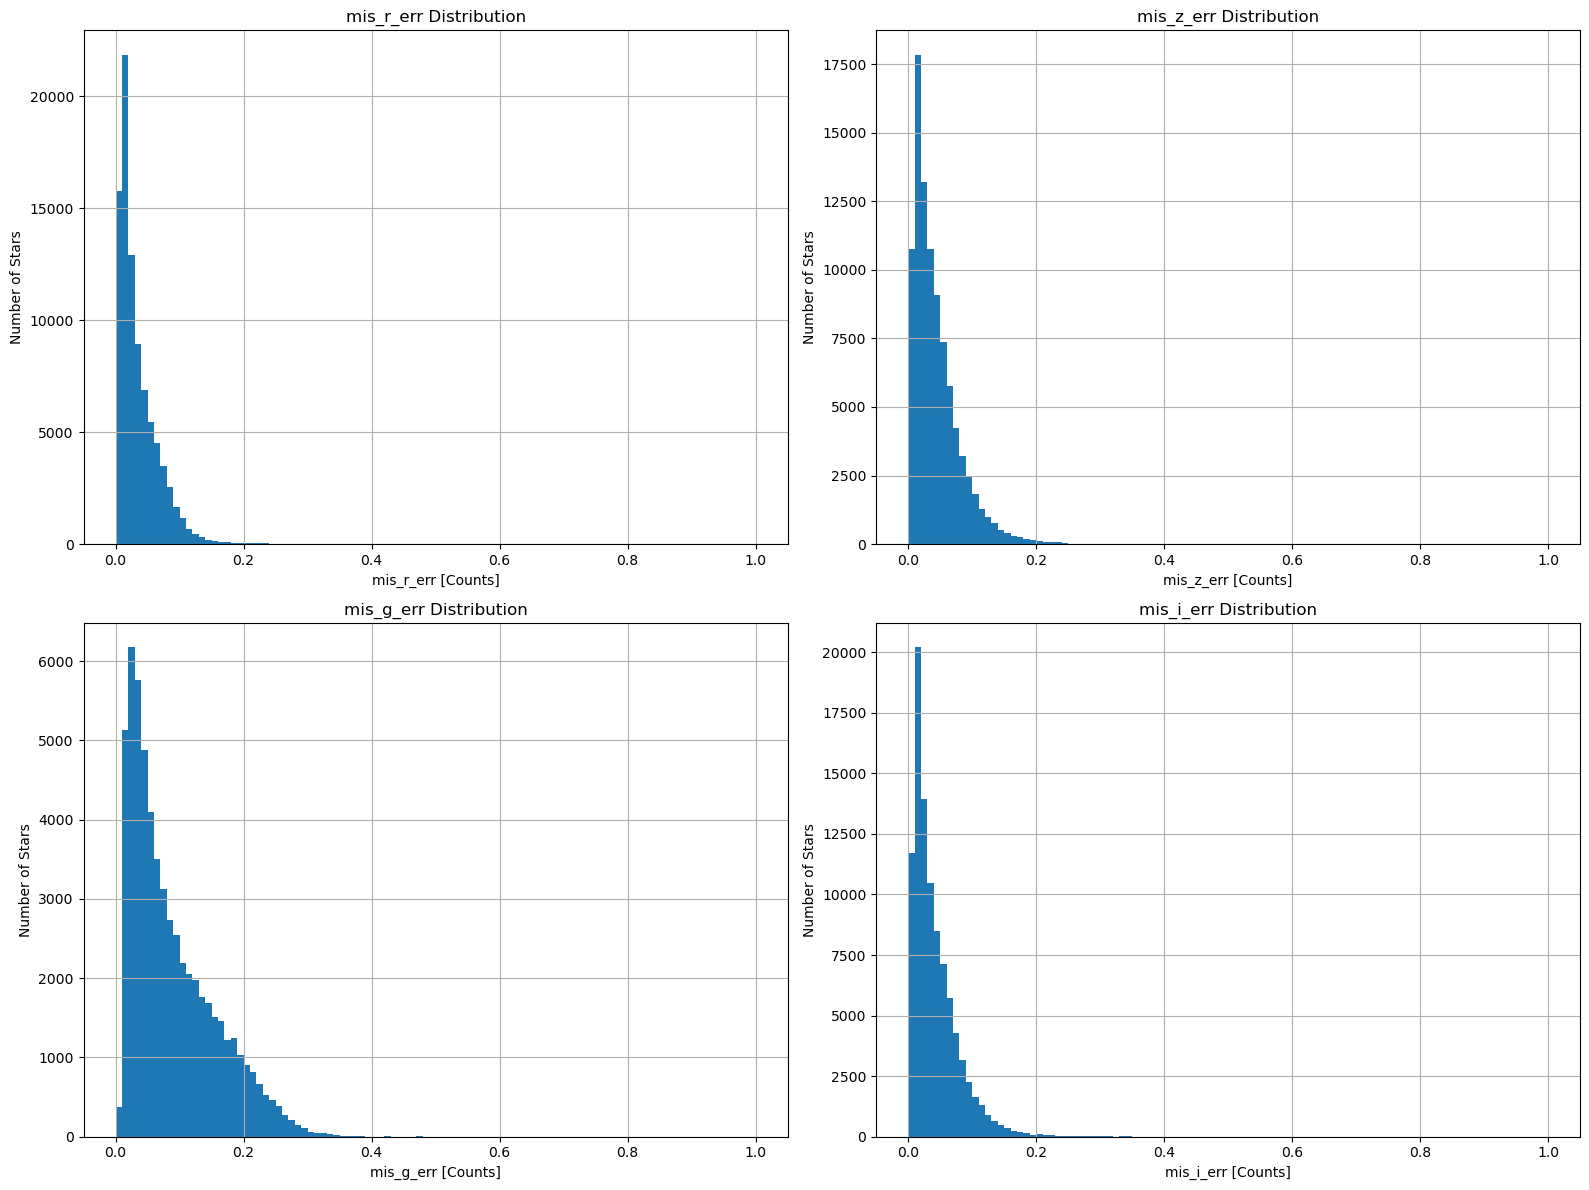

mis_r_err: 0.90    0.076860
0.95    0.094360
0.98    0.118816
0.99    0.142403
Name: mis_r_err, dtype: float64
mis_z_err: 0.90    0.091650
0.95    0.115494
0.98    0.149650
0.99    0.177801
Name: mis_z_err, dtype: float64
mis_g_err: 0.90    0.188813
0.95    0.220930
0.98    0.254233
0.99    0.274890
Name: mis_g_err, dtype: float64
mis_i_err: 0.90    0.087230
0.95    0.110160
0.98    0.140396
0.99    0.165738
Name: mis_i_err, dtype: float64


In [10]:
# mis_mag_err distribution 

# Create one figure with 2 rows × 2 columns, each row height = 6
fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(2, 2, height_ratios=[6, 6])

# === Top-left: mis_r_err Distribution (r-band) ===
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(contents['mis_r_err'], bins=100, range=(0, 1))
ax1.set_xlabel(f"mis_{magnitude_band_1}_err [Counts]")
ax1.set_ylabel(f"Number of Stars")
ax1.set_title(f"mis_{magnitude_band_1}_err Distribution")
ax1.grid(True)

# === Top-right: mis_z_err Distribution (z-band) ===
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(contents['mis_z_err'], bins=100, range=(0, 1))
ax2.set_xlabel(f"mis_{color_band_2}_err [Counts]")
ax2.set_ylabel(f"Number of Stars")
ax2.set_title(f"mis_{color_band_2}_err Distribution")
ax2.grid(True)
             
# === Bottom-left: mis_g_err Distribution (g-band) ===
ax3 = fig.add_subplot(gs[1, 0])
ax3.hist(contents['mis_g_err'], bins=100, range=(0, 1))
ax3.set_xlabel(f"mis_{magnitude_band_2}_err [Counts]")
ax3.set_ylabel(f"Number of Stars")
ax3.set_title(f"mis_{magnitude_band_2}_err Distribution")
ax3.grid(True)

# === Bottom-right: mis_i_err Distribution (i-band) ===
ax4 = fig.add_subplot(gs[1, 1])
ax4.hist(contents['mis_i_err'], bins=100, range=(0, 1))
ax4.set_xlabel(f"mis_{color_band_4}_err [Counts]")
ax4.set_ylabel(f"Number of Stars")
ax4.set_title(f"mis_{color_band_4}_err Distribution")
ax4.grid(True)

plt.tight_layout()
plt.show()
              
# Quantiles
print("mis_r_err:", contents['mis_r_err'].quantile([0.90, 0.95, 0.98, 0.99]))
print("mis_z_err:", contents['mis_z_err'].quantile([0.90, 0.95, 0.98, 0.99]))
print("mis_g_err:", contents['mis_g_err'].quantile([0.90, 0.95, 0.98, 0.99]))
print("mis_i_err:", contents['mis_i_err'].quantile([0.90, 0.95, 0.98, 0.99]))

In [11]:
# === Apply Quality Filters ===
print(contents.shape)

mask_flags = (contents['qflag_r'] == 1) & (contents['qflag_z'] == 1) & (contents['qflag_g'] == 1) & \
             (contents['qflag_i'] == 1)
mask_sky = (contents["Sky_r"] < 50) & (contents["Sky_z"] < 250) & (contents["Sky_g"] < 25) & (contents["Sky_i"] < 170)

mask_err = (contents['mis_r_err'] < 0.2) & (contents['mis_z_err'] < 0.2) & (contents['mis_g_err'] < 0.2) & \
           (contents['mis_i_err'] < 0.2)
# print(contents[['qflag_g', 'qflag_i', 'mis_g_err', 'mis_i_err', 'Sky_g', 'Sky_i']].describe(include='all'))

combined_mask = mask_flags & mask_sky & mask_err
filtered_contents = contents[combined_mask]

print(filtered_contents.shape)

(101166, 67)
(13474, 67)


In [12]:
# === Define Magnitudes and Color ===
r = filtered_contents.loc[:, 'mis_r']
z = filtered_contents.loc[:, 'mis_z']
g = filtered_contents.loc[:, 'mis_g']
i = filtered_contents.loc[:, 'mis_i']
rmz = r - z
gmi = g - i

# === Define Position ===
ra_r = filtered_contents.loc[:, 'RA_r']
dec_r = filtered_contents.loc[:, 'Dec_r']

ra_z = filtered_contents.loc[:, 'RA_z']
dec_z = filtered_contents.loc[:, 'Dec_z']

ra_g = filtered_contents.loc[:, 'RA_g']
dec_g = filtered_contents.loc[:, 'Dec_g']

ra_i = filtered_contents.loc[:, 'RA_i']
dec_i = filtered_contents.loc[:, 'Dec_i']

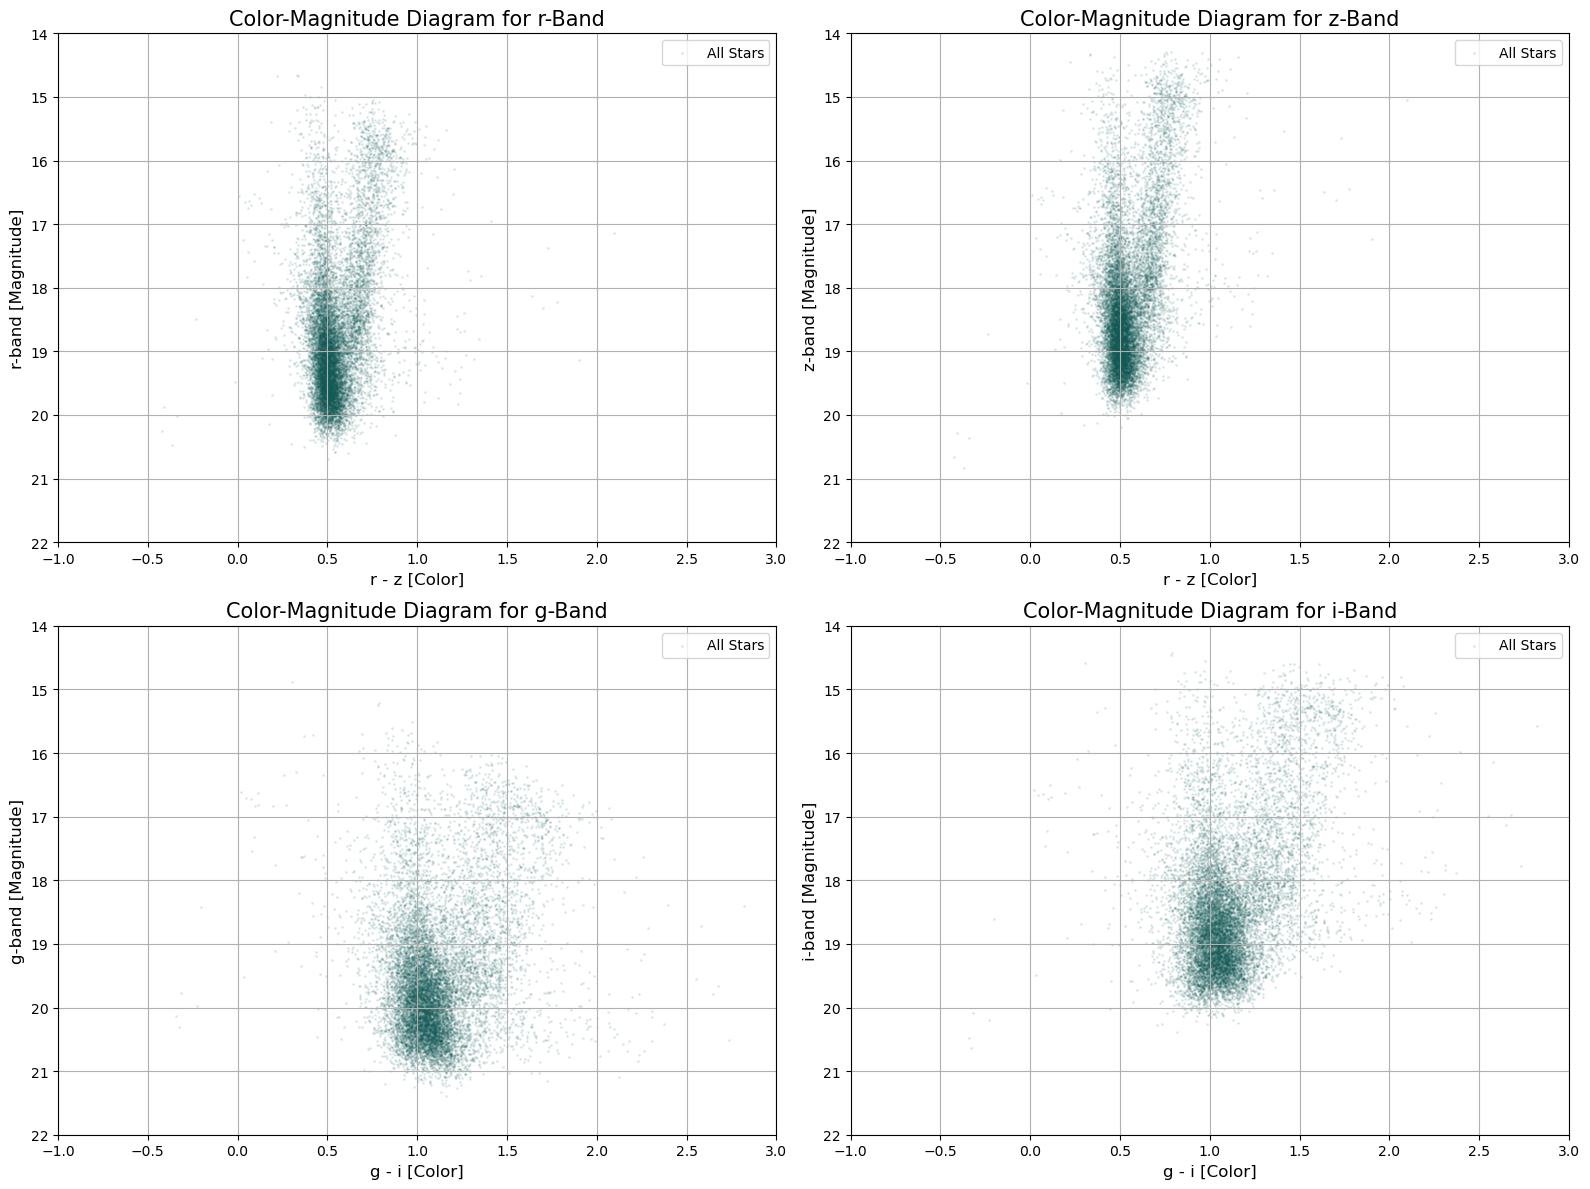

In [13]:
# === Plot CMDs ===
# Create one figure with 2 rows × 2 columns, each row height = 6
fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(2, 2, height_ratios=[6, 6])

# === Top-left: r mag vs. r-z color (r-band) ===
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(rmz, r, s=1, color='#125A56', alpha=0.1, label='All Stars')
ax1.set_xlim(-1, 3)
ax1.set_ylim(14, 22)
ax1.invert_yaxis()
ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax1.set_ylabel(f"{magnitude_band_1}-band [Magnitude]", fontsize = 12)
ax1.set_title("Color-Magnitude Diagram for r-Band", fontsize = 15)
ax1.grid(True)
ax1.legend(loc='best')

# === Top-right: z mag vs. r-z color (z-band) ===
ax2 = fig.add_subplot(gs[0, 1])
ax2.scatter(rmz, z, s=1, color='#125A56', alpha=0.1, label='All Stars')
ax2.set_xlim(-1, 3)
ax2.set_ylim(14, 22)
ax2.invert_yaxis()
ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax2.set_ylabel(f"{color_band_2}-band [Magnitude]", fontsize = 12)
ax2.set_title("Color-Magnitude Diagram for z-Band", fontsize = 15)
ax2.grid(True)
ax2.legend(loc='best')

# === Bottom-left: g mag vs. g-i color (g-band) ===
ax3 = fig.add_subplot(gs[1, 0])
ax3.scatter(gmi, g, s=1, color='#125A56', alpha=0.1, label='All Stars')
ax3.set_xlim(-1, 3)
ax3.set_ylim(14, 22)
ax3.invert_yaxis()
ax3.set_xlabel(f"{color_band_3} - {color_band_4} [Color]", fontsize = 12)
ax3.set_ylabel(f"{magnitude_band_2}-band [Magnitude]", fontsize = 12)
ax3.set_title("Color-Magnitude Diagram for g-Band", fontsize = 15)
ax3.grid(True)
ax3.legend(loc='best')

# === Bottom-right: i mag vs. g-i color (i-band) ===
ax4 = fig.add_subplot(gs[1, 1])
ax4.scatter(gmi, i, s=1, color='#125A56', alpha=0.1, label='All Stars')
ax4.set_xlim(-1, 3)
ax4.set_ylim(14, 22)
ax4.invert_yaxis()
ax4.set_xlabel(f"{color_band_3} - {color_band_4} [Color]", fontsize = 12)
ax4.set_ylabel(f"{color_band_4}-band [Magnitude]", fontsize = 12)
ax4.set_title("Color-Magnitude Diagram for i-Band", fontsize = 15)
ax4.grid(True)
ax4.legend(loc='best')

plt.tight_layout()
plt.show()

In [27]:
# === Red Clump Color Reference Function ===
# The numbers come from the Nataf papers --> Look them up
# l - galactic longitude, b - galactic latitude, our view of a star relative to the galactic center (0, 0)
def red_clump_color(l, b):
    """Returns the expected intrinsic color of the red clump stars given Galactic coordinates."""
    I_0 = 14.3955 - 0.0239 * l + 0.0122 * np.abs(b) # Dereddened I mag of the red clump (rc)
    I_mag = np.array([I_0, I_0 + 0.737, I_0 - 1.07]) # The I mag of the rc, red giant branch (rgbb),
                                                        # and asymptotic giant branch (agbb)
    dis_mod = I_mag - 14.3955 + 5.0 * np.log10(8178.0) - 5.0 # Distance modulus of bar peak density
    distance = 10**(0.2 * (dis_mod + 5.0)) # Distance from ... --> Figure it out
    V_mag = 1.060 + I_mag
    
    # Use the relations between U, B, V, R, I mags and Sloan Digital Sky Survey (SDSS) u, g, r, i, z mags to get 
     # the g, r, i, z mags
    g_sdss = V_mag + 0.553 # g sdss filter (mag)
    r_sdss = V_mag - 0.327 # r sdss  filter (mag)
    i_sdss = V_mag - 0.600 # i sdss filter (mag)
    
    gmi_sdss = g_sdss - i_sdss # (g-i) sdss color
    
    rgbb_r_sdss = 1.060 + I_mag + 0.737 - 0.327 # r sdss filter of the red giant branch
    agbb_r_sdss = 1.060 + I_mag - 1.070 - 0.327 # r sdss filter of the asymptotic giant branch
    rgbb_gmi_sdss = 0.553 + 0.600 - 0.060 # (g-i) sdss color of the red giant branch
    agbb_gmi_sdss = 0.553 + 0.600 + 0.200 # (g-i) sdss color of the asymptotic giant branch
    
    #print("r sdss:", r_sdss, rgbb_r_sdss, agbb_r_sdss)
    #print("gmi sdss:", gmi_sdss, rgbb_gmi_sdss, agbb_gmi_sdss)
    
    # Transforms from SDSS to PanSTARRS
    for i in np.arange(0, 10):
        gpmgs = -0.01808 - 0.13595 * gmi_sdss + 0.01941 * gmi_sdss**2 - 0.00183 * gmi_sdss**3
        rpmrs = -0.01836 - 0.03577 * gmi_sdss + 0.02612 * gmi_sdss**2 - 0.00558 * gmi_sdss**3
        ipmis = 0.01170 - 0.00400 * gmi_sdss + 0.00066 * gmi_sdss**2 - 0.00058 * gmi_sdss**3
        g_ps1 = g_sdss + gpmgs #g panstarrs
        r_ps1 = r_sdss + rpmrs #r panstarrs
        i_ps1 = i_sdss + ipmis #i panstarrs
        gmi_ps1 = g_ps1 - i_ps1 #gmi panstarrs
        rmi_ps1 = r_ps1 - i_ps1 #rmi panstarrs
        imz_ps1 = 0.234625 + 0.211715 * (gmi_ps1 - 1.25) #i-z panstarrs
        rmz_ps1 = rmi_ps1 + imz_ps1 #r-z panstarrs
        z_ps1 = r_ps1 - rmz_ps1 #z panstarrs
        
        print()

    # Return the PanSTARRS magnitudes, distance, and distance modulus as a dictionary
    ret = {"clump-g":g_ps1[0], "clump-r":r_ps1[0], "clump-i":i_ps1[0], "clump-z":z_ps1[0],
           "rgbb-g":g_ps1[1], "rgbb-r":r_ps1[1], "rgbb-i":i_ps1[1], "rgbb-z":z_ps1[1],
           "agbb-g":g_ps1[2], "agbb-r":r_ps1[2], "agbb-i":i_ps1[2], "agbb-z":z_ps1[2],
           "distance":distance[0], "distance_modulus":dis_mod[0]}

    #return zp[0],rmz[0],rp[1]-rp[0],rp[2]-rp[0],gmi[0],dmod[0],d[0]
    #return ip[0],gmi[0],ip[1]-ip[0],ip[2]-ip[0],gmi[0],dmod[0],d[0]

    return ret

In [34]:
ra_r = np.nanmean(ra_r)
dec_r = np.nanmean(dec_r) 

ra_g = np.nanmean(ra_g)
dec_g = np.nanmean(dec_g) 

# Get the l and b coordinates
coords_r = SkyCoord(ra_r, dec_r, frame = 'icrs', unit = u.deg)
l_r = coords_r.galactic.l.value
b_r = coords_r.galactic.b.value

coords_g = SkyCoord(ra_g, dec_g, frame = 'icrs', unit = u.deg)
l_g = coords_g.galactic.l.value
b_g = coords_g.galactic.b.value
global rgbbmag0
global agbbmag0

# Estimate initial red clump guess
red_clump_g = red_clump_color(l_g, b_g)
red_clump_r = red_clump_color(l_r, b_r)

clumpmag0_r = red_clump_r["clump-" + magnitude_band_1]
clumpmag0_z = red_clump_r["clump-" + color_band_2]
clumpmag0_g = red_clump_g["clump-" + magnitude_band_2]
clumpmag0_i = red_clump_g["clump-" + color_band_4]

rgbbmag0_r = red_clump_r["rgbb-" + magnitude_band_1]
rgbbmag0_z = red_clump_r["rgbb-" + color_band_2]
rgbbmag0_g = red_clump_g["rgbb-" + magnitude_band_2]
rgbbmag0_i = red_clump_g["rgbb-" + color_band_4]

agbbmag0_r = red_clump_r["agbb-" + magnitude_band_1]
agbbmag0_z = red_clump_r["agbb-" + color_band_2]
agbbmag0_g = red_clump_g["agbb-" + magnitude_band_2]
agbbmag0_i = red_clump_g["agbb-" + color_band_4]

# Create a dictionary of your values
results = {
    "Red Clump": {
        "r-Band": clumpmag0_r,
        "z-Band": clumpmag0_z,
        "g-Band": clumpmag0_g,
        "i-Band": clumpmag0_i
    },
    "Red Giant Branch": {
        "r-Band": rgbbmag0_r,
        "z-Band": rgbbmag0_z,
        "g-Band": rgbbmag0_g,
        "i-Band": rgbbmag0_i
    },
    "Asymptotic Giant Branch": {
        "r-Band": agbbmag0_r,
        "z-Band": agbbmag0_z,
        "g-Band": agbbmag0_g,
        "i-Band": agbbmag0_i
    }
}

In [35]:
print("Galactic Coordinates in g-mag:", l_r, b_r)
print("Galactic Coordinates in g-mag:", l_g, b_g)

# Print header
print(f"{'Category':<25} {'r-Band':>12} {'z-Band':>12} {'g-Band':>12} {'i-Band':>12}")
print("-" * 75)

# Print values
for category, bands in results.items():
    print(f"{category:<25} {bands['r-Band']:12.6f} {bands['z-Band']:12.6f} "
          f"{bands['g-Band']:12.6f} {bands['i-Band']:12.6f}")

Galactic Coordinates in g-mag: 4.834315385501609 -7.899941508920347
Galactic Coordinates in g-mag: 4.834315833673411 -7.8999413861245
Category                        r-Band       z-Band       g-Band       i-Band
---------------------------------------------------------------------------
Red Clump                    15.075907    14.662970    15.837508    14.843416
Red Giant Branch             15.812907    15.399970    16.574508    15.580416
Asymptotic Giant Branch      14.005907    13.592970    14.767508    13.773416


In [36]:
# === Red Clump Model (Quadratic + Gaussian) for the r-band ===
def rcmodel_r(x, amplitude, slope, magnitude_rc, number_rc, sigma_rc):
    x = np.float64(x)
    A = amplitude*np.exp(slope*(x - magnitude_rc))
    B = number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-magnitude_rc)**2/sigma_rc**2)
    C = 0.201*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+rgbbmag0_r))**2/sigma_rc**2)
    D = 0.028*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+agbbmag0_r))**2/sigma_rc**2)
    return A + B + C + D     

In [37]:
# === Red Clump Model (Quadratic + Gaussian) for the z-band ===
def rcmodel_z(x, amplitude, slope, magnitude_rc, number_rc, sigma_rc):
    x = np.float64(x)
    A = amplitude*np.exp(slope*(x - magnitude_rc))
    B = number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-magnitude_rc)**2/sigma_rc**2)
    C = 0.201*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+rgbbmag0_z))**2/sigma_rc**2)
    D = 0.028*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+agbbmag0_z))**2/sigma_rc**2)
    return A + B + C + D  

In [38]:
# === Red Clump Model (Quadratic + Gaussian) for the g-band ===
def rcmodel_g(x, amplitude, slope, magnitude_rc, number_rc, sigma_rc):
    x = np.float64(x)
    A = amplitude*np.exp(slope*(x - magnitude_rc))
    B = number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-magnitude_rc)**2/sigma_rc**2)
    C = 0.201*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+rgbbmag0_g))**2/sigma_rc**2)
    D = 0.028*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+agbbmag0_g))**2/sigma_rc**2)
    return A + B + C + D     

In [39]:
# === Red Clump Model (Quadratic + Gaussian) for the i-band ===
def rcmodel_i(x, amplitude, slope, magnitude_rc, number_rc, sigma_rc):
    x = np.float64(x)
    A = amplitude*np.exp(slope*(x - magnitude_rc))
    B = number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-magnitude_rc)**2/sigma_rc**2)
    C = 0.201*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+rgbbmag0_i))**2/sigma_rc**2)
    D = 0.028*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+agbbmag0_i))**2/sigma_rc**2)
    return A + B + C + D     

In [40]:
# === Red Clump Gaussian for All Bands ===
def cgauss(x, amplitude, mean, sigma):
    x = np.float64(x)
    return amplitude/(np.sqrt(2*np.pi*sigma**2))*np.exp(-0.5*(x-mean)**2/sigma**2)

In [ ]:
# This cell needs edited
# === Giant Star Selection (r-band) ===
# Filter stars that are likely giants
# Filter for the giants
giant_candidates_r = filtered_contents[(rmz > default_color_cut_rz) & (r < magnitude_cut_rz)]

giant_colors = giant_candidates_r['mis_r'] - giant_candidates_r['mis_z']
giant_magnitudes_r = giant_candidates_r['mis_r']

print(f"Selected {len(giant_candidates)} giant star candidates in the r-band")

# For the magnitude distribution fit of the whole red giant branch
# Create a histogram of magnitudes
hist_counts_giant_r, bin_edges_giant_r = np.histogram(giant_magnitudes_r, range = (magnitude_cut_rz - 4.0, magnitude_cut_rz), bins = 60, density = False) # bins the magnitudes of the giants
bin_centers_giant_r = 0.5 * (bin_edges_giant_r[0:-1] + bin_edges_giant_r[1:]) # calculates bin centers from the bin edges

#bin_edges_giant = np.linspace(min(giant_magnitudes), max(giant_magnitudes), 50)
#bin_centers_giant = 0.5 * (bin_edges_giant[1:] + bin_edges_giant[:-1])
#hist_counts_giant, _ = np.histogram(giant_magnitudes, bins = bin_edges_giant)

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_0 = (hist_counts_giant_r>0)
hist_counts_m0 = hist_counts_giant_r[mask_0]
bin_centers_m0 = bin_centers_giant_r[mask_0]

#print(type(bin_centers_m0))
#print(bin_centers_m0)

initial_guess_0 = [40.0, 0.5, 15.0, 30.0, 0.3] # Initial guess for the curve fit
initial_guess_2 = [15.0, 0.5, 15.8, 50.0, 0.4] 

par_0, cov_0 = spopt.curve_fit(rcmodel_r, bin_centers_m0, hist_counts_m0, p0 = initial_guess_2, sigma = np.sqrt(hist_counts_m0))
print(f"rcmodel Fit Results for the r-Band:\nAmplitude = {par_0[0]:.2f}\n  Slope = {par_0[1]:.2f}\n Magnitude of red clump = {par_0[2]:.2f}\n  Number of red clump stars = {par_0[3]:.2f}\n  Sigma = {par_0[4]:.2f}")

amplitude, slope, magnitude_giant, number_giant, sigma_giant = par_0

# === Giant Star Selection (z-band) ===
giant_candidates_z = filtered_catalog[(color_index > default_color_cut) & (magnitude_values_z < magnitude_cut)]

giant_colors_z = giant_candidates_z[:, c1_col_index] - giant_candidates_z[:, c2_col_index]
giant_magnitudes_z = giant_candidates_z[:, c2_col_index]

print(f"Selected {len(giant_candidates_z)} giant star candidates in the z-band")

hist_counts_giant_z, bin_edges_giant_z = np.histogram(giant_magnitudes_z, range = (magnitude_cut - 4.0,magnitude_cut), bins = 40, density = False) # bins the magnitudes of the giants
bin_centers_giant_z = 0.5 * (bin_edges_giant_z[0:-1] + bin_edges_giant_z[1:]) # calculates bin centers from the bin edges

mask_0z = (hist_counts_giant_z>0)
hist_counts_m0z = hist_counts_giant_z[mask_0z]
bin_centers_m0z = bin_centers_giant_z[mask_0z]

initial_guess_0 = [40.0, 0.5, 15.0, 30.0, 0.3] # Initial guess for the curve fit


par_0z, cov_0z = spopt.curve_fit(rcmodel_z, bin_centers_m0z, hist_counts_m0z, p0 = initial_guess_0, sigma = np.sqrt(hist_counts_m0z))
print(f"rcmodel Fit Results for the z-Band:\nAmplitude = {par_0z[0]:.2f}\n  Slope = {par_0z[1]:.2f}\n Magnitude of red clump = {par_0z[2]:.2f}\n  Number of red clump stars = {par_0z[3]:.2f}\n  Sigma = {par_0z[4]:.2f}")

amplitude, slope, magnitude_giant, number_giant, sigma_giant = par_0z

In [ ]:
# This cell needs edited
# === Red Clump Star Selection (r-band) ===
# Filter stars that are likely within the red clump
clump_candidates = giant_candidates[np.abs(giant_candidates[:, mag_col_index] - par_0[2]) < 2 * par_0[4]]

clump_colors = clump_candidates[:, c1_col_index] - clump_candidates[:, c2_col_index]
clump_magnitudes = clump_candidates[:, mag_col_index]

print(f"Selected {len(clump_candidates)} red clump candidates in the r-band")

# For the color distribution fit of stars in the red clump
# Create a histogram of colors
hist_counts_clump, bin_edges_clump = np.histogram(clump_colors, range = (default_color_cut, default_color_cut + 1.5), bins=60)
bin_centers_clump = 0.5 * (bin_edges_clump[:-1] + bin_edges_clump[1:])

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_1 = (hist_counts_clump>0)
hist_counts_m1 = hist_counts_clump[mask_1]
bin_centers_m1 = bin_centers_clump[mask_1]

# Initial guess for Gaussian parameters: amplitude, mean, sigma
initial_guess_1 = [par_0[3] + 0.0, default_color_cut + 0.2, 0.2]
initial_guess_3 = [70.0, 0.75, 0.2]

par_1, cov_1 = spopt.curve_fit(cgauss, bin_centers_m1, hist_counts_m1, p0 = initial_guess_3, sigma=np.sqrt(hist_counts_m1))
print(f"cgauss Model Fit Results:\nAmplitude = {par_1[0]:.2f}\n  Mean = {par_1[1]:.2f}\n Sigma = {par_1[2]:.2f}")

amplitude, mean, sigma = par_1

# === Red Clump Star Selection (z-band) ===
clump_candidates_z = giant_candidates_z[np.abs(giant_candidates_z[:, c2_col_index] - par_0z[2]) < 2 * par_0z[4]]

clump_colors_z = clump_candidates_z[:, c1_col_index] - clump_candidates_z[:, c2_col_index]
clump_magnitudes_z = clump_candidates_z[:, c2_col_index]

print(f"Selected {len(clump_candidates_z)} red clump candidates in the z-band")

hist_counts_clump_z, bin_edges_clump_z = np.histogram(clump_colors_z, range = (default_color_cut, default_color_cut + 1.5), bins=60)
bin_centers_clump_z = 0.5 * (bin_edges_clump_z[:-1] + bin_edges_clump_z[1:])

mask_1z = (hist_counts_clump_z>0)
hist_counts_m1z = hist_counts_clump_z[mask_1z]
bin_centers_m1z = bin_centers_clump_z[mask_1z]

initial_guess_1 = [par_0z[3] + 0.0, default_color_cut + 0.2, 0.2]
initial_guess_4 = [65.0, 0.75, 0.2]

par_1z, cov_1z = spopt.curve_fit(cgauss, bin_centers_m1z, hist_counts_m1z, p0 = initial_guess_4, sigma=np.sqrt(hist_counts_m1z))
print(f"cgauss Model Fit Results:\nAmplitude = {par_1z[0]:.2f}\n  Mean = {par_1z[1]:.2f}\n Sigma = {par_1z[2]:.2f}")

amplitude, mean, sigma = par_1z

In [41]:
# === Giant Star Selection (g-band) ===
# Filter stars that are likely giants
# Filter for the giants
giant_candidates_g = filtered_contents[(gmi > default_color_cut) & (g < magnitude_cut_g)]

giant_colors_g = giant_candidates_g['mis_g'] - giant_candidates_g['mis_i']
giant_magnitudes_g = giant_candidates_g['mis_g']

print(f"Selected {len(giant_candidates_g)} giant star candidates in the g-band")

# For the magnitude distribution fit of the whole red giant branch
# Create a histogram of magnitudes
hist_counts_giant_g, bin_edges_giant_g = np.histogram(giant_magnitudes_g, range = (magnitude_cut_g - 4.0, magnitude_cut_g), bins = 60, density = False) # bins the magnitudes of the giants
bin_centers_giant_g = 0.5 * (bin_edges_giant_g[0:-1] + bin_edges_giant_g[1:]) # calculates bin centers from the bin edges

#bin_edges_giant = np.linspace(min(giant_magnitudes), max(giant_magnitudes), 50)
#bin_centers_giant = 0.5 * (bin_edges_giant[1:] + bin_edges_giant[:-1])
#hist_counts_giant, _ = np.histogram(giant_magnitudes, bins = bin_edges_giant)

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_0g = (hist_counts_giant_g>0)
hist_counts_m0g = hist_counts_giant_g[mask_0g]
bin_centers_m0g = bin_centers_giant_g[mask_0g]

#print(type(bin_centers_m0))
#print(bin_centers_m0)

initial_guess_2 = [25.0, 0.5, 17.0, 35.0, 0.4] # Initial guess for the curve fit

par_0g, cov_0g = spopt.curve_fit(rcmodel_g, bin_centers_m0g, hist_counts_m0g, p0 = initial_guess_2, sigma = np.sqrt(hist_counts_m0g))
print(f"rcmodel Fit Results for the g-Band:\nAmplitude = {par_0g[0]:.2f}\n  Slope = {par_0g[1]:.2f}\n Magnitude of red clump = {par_0g[2]:.2f}\n  Number of red clump stars = {par_0g[3]:.2f}\n  Sigma = {par_0g[4]:.2f}")

amplitude, slope, magnitude_giant, number_giant, sigma_giant = par_0g

# === Giant Star Selection (i-band) ===
giant_candidates_i = filtered_contents[(gmi > default_color_cut) & (i < magnitude_cut_i)]

giant_colors_i = giant_candidates_i['mis_g'] - giant_candidates_i['mis_i']
giant_magnitudes_i = giant_candidates_i['mis_i']

print(f"Selected {len(giant_candidates_i)} giant star candidates in the i-band")

hist_counts_giant_i, bin_edges_giant_i = np.histogram(giant_magnitudes_i, range=(magnitude_cut_i - 4.0, magnitude_cut_i), bins = 60, density = False) # bins the magnitudes of the giants
bin_centers_giant_i = 0.5 * (bin_edges_giant_i[0:-1] + bin_edges_giant_i[1:]) # calculates bin centers from the bin edges

mask_0i = (hist_counts_giant_i>0)
hist_counts_m0i = hist_counts_giant_i[mask_0i]
bin_centers_m0i = bin_centers_giant_i[mask_0i]

initial_guess_0 = [40.0, 0.5, 15.0, 30.0, 0.3] # Initial guess for the curve fit
initial_guess_2i = [30.0, 0.5, 15.8, 60.0, 0.3]
initial_guess_4 = [20.0, 0.5, 15.35, 25.0, 0.25]

par_0i, cov_0i = spopt.curve_fit(rcmodel_i, bin_centers_m0i, hist_counts_m0i, p0 = initial_guess_4, sigma = np.sqrt(hist_counts_m0i))
print(f"rcmodel Fit Results for the i-Band:\nAmplitude = {par_0i[0]:.2f}\n  Slope = {par_0i[1]:.2f}\n Magnitude of red clump = {par_0i[2]:.2f}\n  Number of red clump stars = {par_0i[3]:.2f}\n  Sigma = {par_0i[4]:.2f}")

amplitude, slope, magnitude_giant, number_giant, sigma_giant = par_0i

Selected 1914 giant star candidates in the g-band
rcmodel Fit Results for the g-Band:
Amplitude = 10.05
  Slope = 1.26
 Magnitude of red clump = 17.09
  Number of red clump stars = 36.47
  Sigma = 0.39
Selected 1676 giant star candidates in the i-band
rcmodel Fit Results for the i-Band:
Amplitude = 12.71
  Slope = 0.90
 Magnitude of red clump = 15.49
  Number of red clump stars = 26.63
  Sigma = 0.35


In [42]:
# === Red Clump Star Selection (g-band) ===
# Filter stars that are likely within the red clump
clump_candidates_g = giant_candidates_g[np.abs(giant_candidates_g['mis_g'] - par_0g[2]) < 2 * par_0g[4]]

clump_colors_g = clump_candidates_g['mis_g'] - clump_candidates_g['mis_i']
clump_magnitudes_g = clump_candidates_g['mis_g']

print(f"Selected {len(clump_candidates_g)} red clump candidates in the g-band")

# For the color distribution fit of stars in the red clump
# Create a histogram of colors
hist_counts_clump_g, bin_edges_clump_g = np.histogram(clump_colors_g, range = (default_color_cut, default_color_cut + 1.5), bins=60)
bin_centers_clump_g = 0.5 * (bin_edges_clump_g[:-1] + bin_edges_clump_g[1:])

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_1g = (hist_counts_clump_g>0)
hist_counts_m1g = hist_counts_clump_g[mask_1g]
bin_centers_m1g = bin_centers_clump_g[mask_1g]

# Initial guess for Gaussian parameters: amplitude, mean, sigma
initial_guess_1 = [par_0g[3] + 0.0, default_color_cut + 0.2, 0.2]

par_1g, cov_1g = spopt.curve_fit(cgauss, bin_centers_m1g, hist_counts_m1g, p0 = initial_guess_1, sigma=np.sqrt(hist_counts_m1g))
print(f"cgauss Model Fit Results:\nAmplitude = {par_1g[0]:.2f}\n  Mean = {par_1g[1]:.2f}\n Sigma = {par_1g[2]:.2f}")

amplitude, mean, sigma = par_1g

# === Red Clump Star Selection (i-band) ===
#clump_candidates_i = giant_candidates_i[np.abs(giant_candidates_i['mis_i'] - par_0i[2]) < 2 * par_0i[4]]
clump_candidates_i = giant_candidates_i[np.abs(giant_candidates_i['mis_i'] - par_0i[2]) < 1.5 * par_0i[4]]
clump_colors_i = clump_candidates_i['mis_g'] - clump_candidates_i['mis_i']
clump_magnitudes_i = clump_candidates_i['mis_i']

print(f"Selected {len(clump_candidates_i)} red clump candidates in the i-band")

hist_counts_clump_i, bin_edges_clump_i = np.histogram(clump_colors_i, range = (default_color_cut, default_color_cut + 1.5), bins=60)
bin_centers_clump_i = 0.5 * (bin_edges_clump_i[:-1] + bin_edges_clump_i[1:])

mask_1i = (hist_counts_clump_i>0)
hist_counts_m1i = hist_counts_clump_i[mask_1i]
bin_centers_m1i = bin_centers_clump_i[mask_1i]

initial_guess_1i = [par_0i[3] + 0.0, default_color_cut + 0.2, 0.2]
initial_guess_3 = [25.0, default_color_cut + 0.2, 0.2]

par_1i, cov_1i = spopt.curve_fit(cgauss, bin_centers_m1i, hist_counts_m1i, p0 = initial_guess_3, sigma=np.sqrt(hist_counts_m1i))
print(f"cgauss Model Fit Results:\nAmplitude = {par_1i[0]:.2f}\n  Mean = {par_1i[1]:.2f}\n Sigma = {par_1i[2]:.2f}")

amplitude, mean, sigma = par_1i

Selected 832 red clump candidates in the g-band
cgauss Model Fit Results:
Amplitude = 20.16
  Mean = 1.44
 Sigma = 0.21
Selected 568 red clump candidates in the i-band
cgauss Model Fit Results:
Amplitude = 13.24
  Mean = 1.50
 Sigma = 0.20
